In [57]:
from astropy import units as u
from astropy.io import fits
from astropy.timeseries import TimeSeries, LombScargle, aggregate_downsample
from astroquery.mast import Observations
from astropy.time import Time

import matplotlib.pyplot as plt
import numpy as np

def get_fits_path(tid, sector):
    ''' Given a TIC ID and sector,
    download the LC file and return the local path
    '''
    obs = Observations.query_criteria(target_name=tid
                                      , provenance_name='SPOC'
                                      , sequence_number=sector)
    prod = Observations.get_product_list(obs)
    lc = Observations.download_products(prod[0])

    fits_path = lc['Local Path'][0]
    return fits_path

def parse_quality(fits_path):
    ''' Read in a fits path, output the times / fluxes
    (remove the "bad quality" values from both)
    Also remove NaNs, or else we can't generate periodograms
    '''
    # Open file, read in the times, SAP flux, and quality flags
    with fits.open(fits_path, mode="readonly") as hdulist:
        tmz = hdulist[1].data['TIME']
        pdc_fluxes = hdulist[1].data['PDCSAP_FLUX']
        quality = hdulist[1].data['QUALITY']
        pdc_error = hdulist[1].data['PDCSAP_FLUX_ERR']
    
    # Convert flags to binary
    bad_bits = np.array([1,2,3,4,5,6,8,10,12,13,15])
    value = 0
    for v in bad_bits:
        value = value + 2**(v-1)
    
    # "bad data" will match the quality flags
    bad_quality = np.bitwise_and(quality, value) >= 1
    
    # Include any NaNs in bad data, 
    nan_data = np.isnan(pdc_fluxes)
    
    # Concat bad quality and NaN indexes
    bad_data = np.logical_or(bad_quality, nan_data)
    
    return tmz[~bad_data], pdc_fluxes[~bad_data], pdc_error[~bad_data]

def bin_lc(t, f, f_err, bs=6*u.min):
    t = Time(t, format='jd')
    ts = TimeSeries({'time':t, 'flux':f, 'flux_err':f_err})
    ts_bin = aggregate_downsample(ts, time_bin_size=bs)
    t_bin = ts_bin['time_bin_start']
    f_bin = ts_bin['flux']
    ferr_bin = ts_bin['flux_err']
    return t_bin, f_bin, ferr_bin
    

def make_pgrm(t, f, f_err):
    f_norm = f/np.median(f)
    f_err = f_err/np.median(f)
    
    # make input freqs
    freqs = np.linspace(0.5, 60, 50000) * u.microhertz
    
    # do psd lombscargle
    LS = LombScargle(t, f_norm, normalization='psd')
    pwrs = LS.power(freqs)
    max_p = max(pwrs)
    
    # get false alarm probability for maximum peak
    LS_err = LombScargle(t, f_norm, f_err, normalization='psd')
    max_pwr_err = LS_err.power(freqs).max()
    print(LS_err.false_alarm_level(0.997), max_p, max_pwr_err)
    sigma3 = float(LS_err.false_alarm_level(0.997))*max_p/max_pwr_err
    
    # special correction to convert to amplitude
    pwrs = np.sqrt(pwrs) * np.sqrt(4.0 / len(t))
    sigma3 = np.sqrt(sigma3) * np.sqrt(4.0 / len(t))
    return freqs, pwrs, sigma3
    

def make_plots(t, f, freqs, pwrs, sigma3):
    f_norm = f/np.nanmedian(f)
    fig, (ax1,ax2) = plt.subplots(1,2, figsize=(12,5), gridspec_kw={'width_ratios':[3,1]})
    # plot lc
    ax1.scatter(t ,(f_norm-1)*100 ,c='black',s=2)
    ax1.set_xlabel('TESS day')
    ax1.set_ylabel('amplitude [%]')
    
    # plot prgm
    ax2.plot(freqs, pwrs*100, c='black')
    ax2.set_xlabel('Frequency [$\mu$Hz]')
    ax2.set_ylabel('amplitude [%]')
    ax2.hlines(sigma3*100, freqs[0].value, freqs[-1].value, linestyles='dashed', colors='tab:orange')
    
    # Set up period at top
    def invert(x):
        # 1/x with special treatment of x == 0
        x = np.array(x).astype(float)
        near_zero = np.isclose(x, 0)
        x[near_zero] = np.inf
        x[~near_zero] = 277.77778 / x[~near_zero]
        return np.around(x, decimals=1)
    per_ax2 = ax2.secondary_xaxis('top', functions=(invert, invert))
    per_ax2.set_xticks(invert(freqs)[2000::11999])
    per_ax2.set_xlabel('Period [h]')


In [32]:
# Get the path to the fits file
fits_path = get_fits_path(442871031, 32)

INFO: Found cached file ./mastDownload/TESS/tess2020324010417-s0032-0000000442871031-0200-s/tess2020324010417-s0032-0000000442871031-0200-s_lc.fits with expected size 1903680. [astroquery.query]


In [99]:
# Open the fits file, parse quality flags, and return time, flux, and error
t, flux, err = parse_quality(fits_path)

In [100]:
# Bin the light curve
t, flux, err = bin_lc(t, flux, err)

In [104]:
freqs, amps, sigma3 = make_pgrm(t[~flux.data.mask].value*u.day, flux.data.compressed(), err.data.compressed())

8.983884754893921 0.0032144196450291543 737746.252876924


In [87]:
len(flux.data.compressed())

5875

In [90]:
len(t)

6215

In [103]:
t[~flux.data.mask]

<Time object: scale='utc' format='jd' value=[2174.23447009 2174.23863676 2174.24280343 ... 2200.11780343 2200.12197009
 2200.12613676]>

In [98]:
6215-5875

340

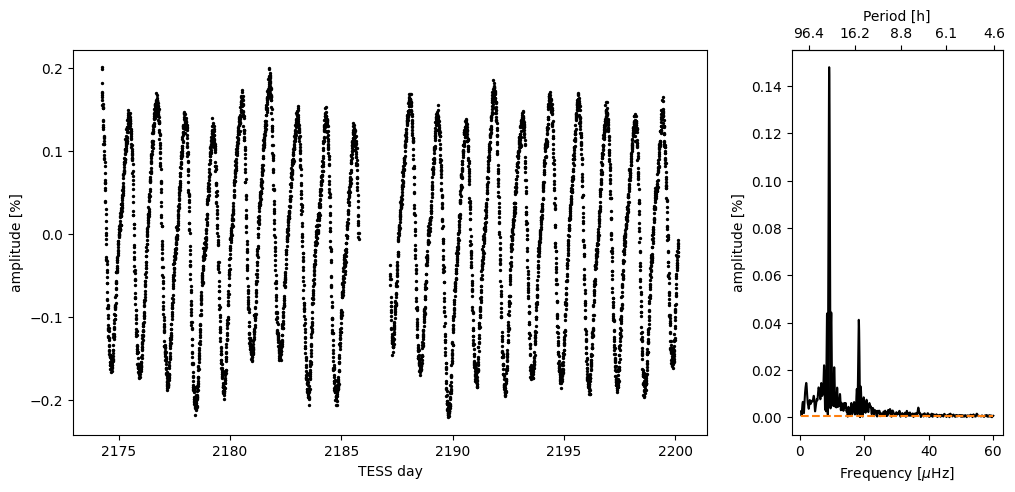

In [107]:
make_plots(t[~flux.data.mask].value, flux.data.compressed(), freqs, amps, sigma3)

ValueError: x and y must be the same size

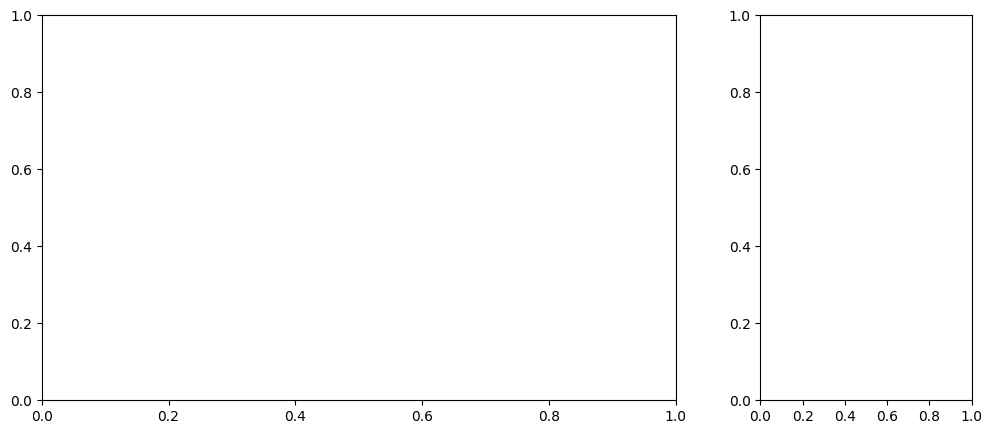

In [111]:
make_plots(t[t.mask].value, flux.data.compressed(), freqs, amps, sigma3)

In [67]:
a = np.nan

In [72]:
np.nanmean([a, a, a])

/var/folders/k2/y3j3v6y12kqf4z318skr1qkc0004v5/T/ipykernel_68466/3489902368.py:1: RuntimeWarning: Mean of empty slice
  np.nanmean([a, a, a])


nan

In [73]:
np.where(flux<10)

(array([1261, 2770, 2771, 2772, 2773, 2774, 2775, 2776, 2777, 2778, 2779,
        2780, 2781, 2782, 2783, 2784, 2785, 2786, 2787, 2788, 2789, 2790,
        2791, 2792, 2793, 2794, 2795, 2796, 2797, 2798, 2799, 2800, 2801,
        2802, 2803, 2804, 2805, 2806, 2807, 2808, 2809, 2810, 2811, 2812,
        2813, 2814, 2815, 2816, 2817, 2818, 2819, 2820, 2821, 2822, 2823,
        2824, 2825, 2826, 2827, 2828, 2829, 2830, 2831, 2832, 2833, 2834,
        2835, 2836, 2837, 2838, 2839, 2840, 2841, 2842, 2843, 2844, 2845,
        2846, 2847, 2848, 2849, 2850, 2851, 2852, 2853, 2854, 2855, 2856,
        2857, 2858, 2859, 2860, 2861, 2862, 2863, 2864, 2865, 2866, 2867,
        2868, 2869, 2870, 2871, 2872, 2873, 2874, 2875, 2876, 2877, 2878,
        2879, 2880, 2881, 2882, 2883, 2884, 2885, 2886, 2887, 2888, 2889,
        2890, 2891, 2892, 2893, 2894, 2895, 2896, 2897, 2898, 2899, 2900,
        2901, 2902, 2903, 2904, 2905, 2906, 2907, 2908, 2909, 2910, 2911,
        2912, 2913, 2914, 2915, 2916, 

In [82]:
flux[2765:2780].data.filled(np.nan)

array([2622366.2, 2621989. , 2621862. , 2621980. , 2621792.2,       nan,
             nan,       nan,       nan,       nan,       nan,       nan,
             nan,       nan,       nan], dtype='>f4')

In [80]:
type(flux)

astropy.table.column.MaskedColumn